# Two-operation rules, "sequence of rigid transformations" prompt — 3 models × 1/3/5/7/9 examples

**Prompt header** (notebooks 48-50 header plus one sentence):

> Each example below shows a 6x6 grid of digits (Input) and the grid obtained by applying the same hidden
> transformation to it (Output). The transformation is the same for every example. The hidden transformation is a
> sequence of one or more rigid transformations (distance-preserving maps) of the grid, where the grid wraps around
> at its edges.

No operation is named, and the number of steps is not given.

**Two experiments per task:**
* `answer`: give the transformed grid only.
* `steps`: "break the transformation down into the steps it is made of", one `<step>` per step, then the
  final grid. No intermediate grids are requested.

**Tasks.** The 6 two-operation rules AB, AC, BA, BC, CA, CB (A = shift rows right, B = rotate 90° clockwise,
C = mirror left-right); 20 tasks each. Examples are **nested**: each task has 9 examples, and the run with n examples
uses the first n, with the same query grid. The first example alone already determines the rule uniquely.

**Models:** `openai/gpt-6-luna`, `meta/muse-glimmer-30b` (each with its default reasoning). `openai/gpt-6.2-astra` is
left out for now because of its price; add it to `MODELS` to run it on the same tasks later.
**Size:** 120 tasks × 5 example counts × 2 experiments × 2 models = **2,400 calls** (about $5-6).

Cell 4 = dry run (no cost). Cell 5 = pilot: 2 calls per model (checks model IDs and output format).
Cell 6 = full run (resumable). Cell 7 = tables, figure and zip.


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 7406f546bc8048aa0fc2386a529229010348c2d5


In [6]:
# --- 3. Configuration ---------------------------------------------------------------------------------------------
MODELS = ["openai/gpt-6-luna", "meta/muse-glimmer-30b"]     # "openai/gpt-6.2-astra" left out for now (cost)
DEMO_COUNTS = [1, 3, 5, 7, 9]
N_PER_WORD = 20
TASK_SEED = 0
EXPERIMENTS = ["answer", "steps"]
STYLE = "steps"                  # header: sequence of rigid transformations, wrap-around grid
REASONING = None                 # None = each model's default
MAX_TOKENS = None
WORKERS = 256
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
if IN_COLAB and not os.environ.get("OPENROUTER_API_KEY"):
    from google.colab import userdata
    os.environ["OPENROUTER_API_KEY"] = userdata.get("OPENROUTER_API_KEY")      # never printed
print("OpenRouter key present:", bool(os.environ.get("OPENROUTER_API_KEY")))
import json, pathlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_rows", 300); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 250)
from decompositionality import icl_api as IA
_tag = "default" if not REASONING else "_".join(f"{k}{v}" for k, v in REASONING.items())
OUT_ROOT = pathlib.Path(RESULTS_ROOT) / "icl_api" / f"k2_rigid_steps_n{N_PER_WORD}_seed{TASK_SEED}_{_tag}"
OUT_ROOT.mkdir(parents=True, exist_ok=True)
path = lambda m, n: OUT_ROOT / m.replace("/", "_") / f"demos{n}.jsonl"
print("results ->", OUT_ROOT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OpenRouter key present: True
results -> /content/drive/MyDrive/decompositionality_results/icl_api/k2_rigid_steps_n20_seed0_default


In [3]:
# --- 4. Dry run: build the tasks and show both prompts (no API calls) -----------------------------------------------
tasks = IA.make_nested_tasks(IA.K2_WORDS, n_per_word=N_PER_WORD, max_demos=max(DEMO_COUNTS), seed=TASK_SEED)
(OUT_ROOT / "tasks.json").write_text(json.dumps(tasks))
print(len(tasks), "tasks")
for e in EXPERIMENTS:
    print(f"\n==================== experiment '{e}' (task {tasks[0]['task_id']}, 1 example) ====================")
    print(IA.build_prompt(IA.with_demos(tasks, 1)[0], e, hint=False, style=STYLE))
print("\ncalls planned:", len(tasks) * len(DEMO_COUNTS) * len(EXPERIMENTS) * len(MODELS))


120 tasks

==================== experiment 'answer' (task AB-000, 1 example) ====================
Each example below shows a 6x6 grid of digits (Input) and the grid obtained by applying the same hidden transformation to it (Output). The transformation is the same for every example. The hidden transformation is a sequence of one or more rigid transformations (distance-preserving maps) of the grid, where the grid wraps around at its edges.

Example 1
Input:
4 0 2 4 1 1
9 0 3 6 5 1
9 3 7 8 3 4
1 8 8 7 1 3
4 0 5 0 0 8
6 1 3 2 2 8
Output:
8 8 3 4 1 1
6 4 1 9 9 4
1 0 8 3 0 0
3 5 8 7 3 2
2 0 7 8 6 4
2 0 1 3 5 1

Apply the same transformation to this grid:
6 6 8 3 9 5
6 7 9 1 1 4
1 8 9 8 1 5
0 6 6 1 9 5
4 4 9 7 6 0
9 4 3 9 5 8

Give your answer as a 6x6 grid of digits in the same format (6 lines of 6 space-separated digits), between <answer> and </answer>.

==================== experiment 'steps' (task AB-000, 1 example) ====================
Each example below shows a 6x6 grid of digits (Input

In [4]:
# --- 5. Pilot: 2 calls per model (3 examples) ------------------------------------------------------------------------
for m in MODELS:
    IA.run(IA.with_demos(tasks, 3)[:1], path(m, 3), m, experiments=EXPERIMENTS, hint=False, style=STYLE,
           reasoning=REASONING, max_tokens=MAX_TOKENS, workers=WORKERS)
    for line in path(m, 3).read_text().splitlines()[-2:]:
        r = json.loads(line)
        u = r.get("usage") or {}
        print(f"--- {m} / {r['experiment']}  error={r['error']}  prompt_tokens={u.get('prompt_tokens')}  "
              f"completion_tokens={u.get('completion_tokens')}  cost=${u.get('cost')}\n{(r['content'] or '')[:1500]}\n")


0 calls already done; 2 to run (model openai/gpt-6-luna)
  2/2 calls finished (2 ok)
--- openai/gpt-6-luna / answer  error=None  prompt_tokens=646  completion_tokens=1364  cost=$0.0007466
<answer>
8 0 5 5 4 5
9 4 0 1 6 6
4 4 6 8 7 6
3 9 6 9 9 8
9 7 1 8 1 3
5 6 9 1 1 9
</answer>

--- openai/gpt-6-luna / steps  error=None  prompt_tokens=677  completion_tokens=1255  cost=$0.0006952
<step>Rotate the grid 90° clockwise.</step>
<step>Shift every row down by one position, wrapping the bottom row to the top.</step>

<answer>
8 0 5 5 4 5
9 4 0 1 6 6
4 4 6 8 7 6
3 9 6 9 9 8
9 7 1 8 1 3
5 6 9 1 1 9
</answer>

0 calls already done; 2 to run (model meta/muse-glimmer-30b)
  2/2 calls finished (2 ok)
--- meta/muse-glimmer-30b / steps  error=None  prompt_tokens=726  completion_tokens=16187  cost=$0.02451972
<step>Rotate the whole grid 90° clockwise with wrap-around, i.e. (r,c) → (r₁,c₁) = (c , -r mod 6).</step>
<step>Translate the rotated grid down by 1 row and left by 1 column with wrap-around, i.e. 

In [7]:
# --- 6. Full run (resumable: calls already saved are skipped) --------------------------------------------------------
for m in MODELS:
    for n in DEMO_COUNTS:
        print(f"=== {m}, {n} examples")
        IA.run(IA.with_demos(tasks, n), path(m, n), m, experiments=EXPERIMENTS, hint=False, style=STYLE,
               reasoning=REASONING, max_tokens=MAX_TOKENS, workers=WORKERS)


=== openai/gpt-6-luna, 1 examples
240 calls already done; 0 to run (model openai/gpt-6-luna)
=== openai/gpt-6-luna, 3 examples
191 calls already done; 49 to run (model openai/gpt-6-luna)
  10/49 calls finished (10 ok)
  20/49 calls finished (20 ok)
  30/49 calls finished (30 ok)
  40/49 calls finished (40 ok)
  49/49 calls finished (49 ok)
=== openai/gpt-6-luna, 5 examples
0 calls already done; 240 to run (model openai/gpt-6-luna)
  10/240 calls finished (10 ok)
  20/240 calls finished (20 ok)
  30/240 calls finished (30 ok)
  40/240 calls finished (40 ok)
  50/240 calls finished (50 ok)
  60/240 calls finished (60 ok)
  70/240 calls finished (70 ok)
  80/240 calls finished (80 ok)
  90/240 calls finished (90 ok)
  100/240 calls finished (100 ok)
  110/240 calls finished (110 ok)
  120/240 calls finished (120 ok)
  130/240 calls finished (130 ok)
  140/240 calls finished (140 ok)
  150/240 calls finished (150 ok)
  160/240 calls finished (160 ok)
  170/240 calls finished (170 ok)
  180

Accuracy by model, experiment and number of examples:


model      meta/muse-glimmer-30b        openai/gpt-6-luna       
experiment                answer  steps            answer  steps
n_demos                                                         
1                          0.992  0.967             0.900  0.883
3                          0.992  0.983             0.892  0.833
5                          0.975  0.925             0.892  0.883
7                          0.983  0.975             0.917  0.867
9                          0.975  0.933             0.892  0.858


Accuracy by rule (all example counts):


model      meta/muse-glimmer-30b       openai/gpt-6-luna      
experiment                answer steps            answer steps
word                                                          
AB                          0.97  0.92              0.76  0.75
AC                          0.99  0.92              0.98  0.97
BA                          1.00  0.99              0.93  0.79
BC                          0.99  0.99              1.00  1.00
CA                          0.97  0.98              0.90  0.86
CB                          0.98  0.94              0.82  0.82

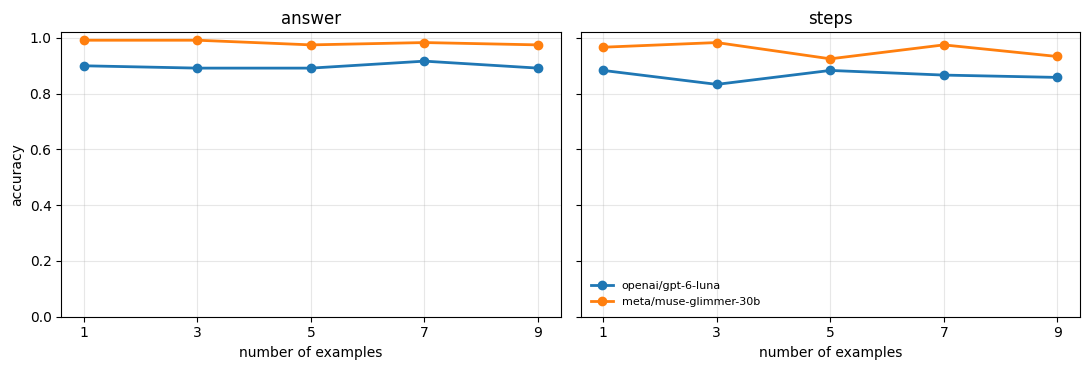


Error types:


error_type                        correct  execution slip  other wrong grid  unparsed  wrong transform
model                 experiment                                                                      
meta/muse-glimmer-30b answer        0.983           0.000             0.000     0.010            0.007
                      steps         0.957           0.003             0.002     0.032            0.007
openai/gpt-6-luna     answer        0.898           0.060             0.017     0.010            0.015
                      steps         0.865           0.057             0.017     0.013            0.048


Number of steps the model writes (rows: model, columns: number of steps):


n_steps                     0.0  1.0  2.0  3.0
model                 word                    
meta/muse-glimmer-30b AB      5    1   89    5
                      AC      7   33   60    0
                      BA      1   92    7    0
                      BC      1   97    2    0
                      CA      0   99    1    0
                      CB      4    4   73   19
openai/gpt-6-luna     AB      0    5   81   14
                      AC      0   57   43    0
                      BA      0   50   43    7
                      BC      0  100    0    0
                      CA      0  100    0    0
                      CB      0   77   22    1


Example decompositions (3 examples, first 2 tasks per rule):


,model,word,correct,n_steps,steps_text
241,openai/gpt-6-luna,AB,True,2.0,"Rotate the grid 90° clockwise. | Shift every row down by one position, wrapping the bottom row to the top."
245,openai/gpt-6-luna,AB,True,2.0,"Rotate the grid 90° clockwise. | Shift the rotated grid up by one row, wrapping the top row around to the bottom."
267,openai/gpt-6-luna,AC,False,2.0,"Reflect the grid left-to-right, reversing the order of the digits in each row. | Shift the reflected grid one column to the left, wrapping the leftmost column around to the right."
270,openai/gpt-6-luna,AC,True,2.0,"Reflect the grid left-to-right, reversing the order of the digits in each row. | Shift each row one position to the left, wrapping the leftmost digit around to the right."
314,openai/gpt-6-luna,BA,True,2.0,"Transpose the grid, so each row becomes a column of the original grid. | In each resulting row, keep the first digit fixed and reverse the order of the remaining five digits. Because the grid wraps around, this is a 90° rotation on the torus."
319,openai/gpt-6-luna,BA,True,1.0,"Rotate the grid on the wrapped 6×6 grid so that each output cell at row r, column c takes the input cell at row (−c mod 6), column r. Equivalently, output row r reads input column r in the order of input rows 0, 5, 4, 3, 2, 1."
339,openai/gpt-6-luna,BC,True,1.0,"Transpose the grid across its main diagonal: swap each cell’s row and column coordinates. Equivalently, make each output row one column of the input."
341,openai/gpt-6-luna,BC,True,1.0,"Reflect the grid across its main diagonal, swapping rows and columns (equivalently, transpose the grid)."
398,openai/gpt-6-luna,CA,True,1.0,"Reflect each row horizontally around its first column: keep the first digit in place, then reverse the order of the remaining five digits."
399,openai/gpt-6-luna,CA,True,1.0,"Reflect the grid horizontally, keeping the first and fourth columns fixed. Because the grid wraps, this reverses the column order to 1, 6, 5, 4, 3, 2."



Usage per call:


prompt_tokens  completion_tokens  reasoning_tokens  cost_usd
model                 experiment                                                              
meta/muse-glimmer-30b answer              999.0         10067.7533         8533.0550    0.0128
                      steps              1030.0         12502.9633        10873.4717    0.0160
openai/gpt-6-luna     answer              950.0          1542.1250         1458.0517    0.0009
                      steps               981.0          1816.8233         1691.8450    0.0010

total cost by model ($): {'meta/muse-glimmer-30b': 17.3, 'openai/gpt-6-luna': 1.14}
saved to /content/drive/MyDrive/decompositionality_results/icl_api/k2_rigid_steps_n20_seed0_default


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# --- 7. Tables and figure --------------------------------------------------------------------------------------------
df = pd.concat([IA.score(IA.with_demos(tasks, n), path(m, n)).assign(model=m, n_demos=n)
                for m in MODELS for n in DEMO_COUNTS if path(m, n).exists()], ignore_index=True)
print("Accuracy by model, experiment and number of examples:")
display(df.pivot_table(index="n_demos", columns=["model", "experiment"], values="correct").round(3))
print("\nAccuracy by rule (all example counts):")
display(df.pivot_table(index="word", columns=["model", "experiment"], values="correct").round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, e in zip(axes, EXPERIMENTS):
    for m in MODELS:
        q = df[(df.model == m) & (df.experiment == e)].groupby("n_demos").correct.mean()
        ax.plot(q.index, q.values, marker="o", lw=2, label=m)
    ax.set(title=e, xlabel="number of examples", xticks=DEMO_COUNTS, ylim=(0, 1.02)); ax.grid(alpha=.3)
axes[0].set_ylabel("accuracy"); axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(OUT_ROOT / "accuracy.png", dpi=150); plt.show()
print("\nError types:")
display(df.groupby(["model", "experiment"]).error_type.value_counts(normalize=True).unstack(fill_value=0).round(3))
s = df[df.experiment == "steps"]
print("\nNumber of steps the model writes (rows: model, columns: number of steps):")
display(pd.crosstab([s.model, s.word], s.n_steps))
print("\nExample decompositions (3 examples, first 2 tasks per rule):")
display(s[s.n_demos == 3].groupby(["model", "word"]).head(2)[["model", "word", "correct", "n_steps", "steps_text"]])
print("\nUsage per call:")
display(df[["prompt_tokens", "completion_tokens", "reasoning_tokens", "cost_usd"]].apply(pd.to_numeric, errors="coerce")
        .groupby([df.model, df.experiment]).mean().round(4))
print("total cost by model ($):", df.assign(c=pd.to_numeric(df.cost_usd, errors="coerce")).groupby("model").c.sum().round(2).to_dict())
df.to_csv(OUT_ROOT / "scores.csv", index=False)
print("saved to", OUT_ROOT)
if IN_COLAB:
    import shutil
    from google.colab import files
    shutil.make_archive(str(OUT_ROOT), "zip", OUT_ROOT)
    files.download(str(OUT_ROOT) + ".zip")
